# Solar filament instance segmentation — full pipeline

MAGFiLO / IEEE BigData Cup 2026. Reproduces the final submission (U-Net ResNet34 + U-Net EfficientNet-B3 ensemble, 8-view TTA, LightGBM instance scorer; grouped 5-fold CV PQ 0.432).

Every step is skipped when its outputs already exist; set `RETRAIN = True` to recompute everything from the raw competition data (~12 h on a 4 GB RTX 3050).

In [1]:
import os, sys, json, subprocess
import numpy as np, pandas as pd

RETRAIN = False
ROOT = os.path.abspath('.')
S2 = os.path.join(ROOT, 'runs', 'filament-segmentation-2026', 'stage2_modeling')
sys.path.insert(0, S2)

def run(*args):
    """Run a pipeline script from the modeling dir and stream its last lines."""
    out = subprocess.run([sys.executable, *args], cwd=S2, capture_output=True, text=True,
                         env={**os.environ, 'PYTHONWARNINGS': 'ignore'})
    print('\n'.join((out.stdout + out.stderr).strip().splitlines()[-6:]))
    out.check_returncode()

def done(path):
    return os.path.exists(os.path.join(S2, path)) and not RETRAIN

## 1. Data
Download with `kaggle competitions download -c filament-segmentation-2026` into `runs/filament-segmentation-2026/data/raw/` and unzip. `prep_data.py` turns the COCO polygons into one instance label map per annotation set (images have 1–3 independent annotators).

In [2]:
if not done('../data/processed/index.csv'):
    run('prep_data.py')
idx = pd.read_csv(os.path.join(S2, '..', 'data', 'processed', 'index.csv'))
print(len(idx), 'annotation sets on', idx.stem.nunique(), 'images')
print('annotation sets per image:', idx.groupby('stem').size().value_counts().sort_index().to_dict())
print('filaments per set: median', idx.n_filaments.median(), 'max', idx.n_filaments.max())

1154 annotation sets on 707 images
annotation sets per image: {1: 411, 2: 145, 3: 151}
filaments per set: median 7.0 max 26


## 2. Metric and validation
`pq.py` re-implements the host PQ exactly: loop over annotation sets, every pair with IoU > 0.5 is a TP, counts pooled over all sets. Scoring each annotator against the others gives the human agreement level. CV is GroupKFold(5) by physical image (`folds.csv`).

In [3]:
from pipeline import make_folds, gt_maps_for
from pq import PQAccumulator
acc = PQAccumulator()
for stem, g in idx.groupby('stem'):
    if len(g) < 2: continue
    maps = gt_maps_for(stem, 1024, idx)
    for i in range(len(maps)):
        for j in range(len(maps)):
            if i != j: acc.add(maps[j], maps[i])
print('human vs human PQ (1024 px):', acc.summary())
print(make_folds().fold.value_counts().sort_index().to_dict())

human vs human PQ (1024 px): {'pq': 0.33854, 'sq': 0.6345, 'tp': 4268, 'fp': 3731, 'fn': 3731}
{0: 142, 1: 142, 2: 141, 3: 141, 4: 141}


## 3. Train the two ensemble members
U-Net, 1-channel input resized to 1024, random 768 crops, soft annotator-mean target, BCE + 0.5 soft-Dice, 30 epochs. `pipeline.py all` = train (fold-resumable) → OOF → post-processing grid → test inference.

In [4]:
MEMBERS = ['2026-10-11-unet-r34-1024-crop768', '2026-10-12-unet-effb3-1024-crop768']
for r in MEMBERS:
    if not done(f'runs/{r}/cv_score.json'):
        run('pipeline.py', 'all', '--config', f'runs/{r}/config.yaml')
    print(r, json.load(open(os.path.join(S2, 'runs', r, 'cv_score.json')))['mean'])

2026-10-11-unet-r34-1024-crop768 0.40861
2026-10-12-unet-effb3-1024-crop768 0.41346


## 4. 8-view TTA re-inference
Same weights, OOF and test probabilities recomputed with all 8 dihedral views.

In [5]:
TTA8 = [r.replace('2026-10-11-unet', '2026-10-12-unet') + '-tta8' for r in MEMBERS]
for src, dst in zip(MEMBERS, TTA8):
    if not done(f'runs/{dst}/test_preds.csv'):
        run('reinfer.py', '--src', src, '--dst', dst, '--tta', '8')
        run('pipeline.py', 'tune', '--config', f'runs/{dst}/config.yaml')
        run('pipeline.py', 'predict', '--config', f'runs/{dst}/config.yaml')
    print(dst, json.load(open(os.path.join(S2, 'runs', dst, 'cv_score.json')))['mean'])

2026-10-12-unet-r34-1024-crop768-tta8 0.41264
2026-10-12-unet-effb3-1024-crop768-tta8 0.41729


## 5. Ensemble + instance scorer
Probabilities averaged 50/50. Components at threshold 0.3 are scored by LightGBM, which predicts the mean matched IoU across annotators; the host PQ adds exactly n/2 to its denominator per kept instance, so a component is worth keeping iff that value exceeds PQ/2.

In [6]:
ENS = '2026-10-12-ens-r34-effb3-768-tta8'
members = [f'runs/{r}' for r in TTA8]
if not done(f'runs/{ENS}/test_probs'):
    run('ensemble.py', '--out', ENS, '--runs', *TTA8)
if not done(f'runs/{ENS}/scorer_v2/scorer_cv_t0.3.json'):
    run('scorer.py', '--run', f'runs/{ENS}', '--thr', '0.3', '--v2', '--members', *members)
cv = json.load(open(os.path.join(S2, 'runs', ENS, 'scorer_v2', 'scorer_cv_t0.3.json')))
print('final CV PQ', cv['pq'], 'tau', cv['best_tau'], 'per fold', cv['per_fold'])

final CV PQ 0.43165 tau 0.23 per fold {'0': 0.45082, '1': 0.42784, '2': 0.42036, '3': 0.43371, '4': 0.42219}


## 6. Submission
Selected components are re-thresholded on the upsampled 2048 map and RLE-encoded; the validator checks ids, empty/overlapping masks and orientation.

In [7]:
sub_path = f'runs/{ENS}/test_preds_scorer_v2.csv'
if not done(sub_path):
    run('scorer.py', '--run', f'runs/{ENS}', '--thr', '0.3', '--v2', '--members', *members, '--predict')
run('validate_submission.py', sub_path)
pd.read_csv(os.path.join(S2, sub_path)).head()

rows=1066 images=177/180 empty=0 overlapping_masks=0
orientation: mask-darkness 323.0 vs transposed 2881.2 (mask should be darker = more negative)
VALID


,filament_id,segmentation_rle
0,20110120105534Ch_1,l_Vi22mo14M101N110gPNKcn16\QNKen15ZQNKen16ZQNJ...
1,20110120105534Ch_2,XjnP24jo12O1O1O00001N101N1000O10O100O0100O10K5...
2,20110130110334Ch_1,c_ld22lo18I4L2O4L2N2O000mPN_Ogn1`0VQNBln1h01O1...
3,20110214175414Mh_1,W]d[29eo13M3M2J7N2N101N1ROUOgRNl0Vm1XOhRNh0Wm1...
4,20110214175414Mh_2,^^`d24ko12O1N100O2O010O001O10O000000O10000O010...


## 7. Qualitative check

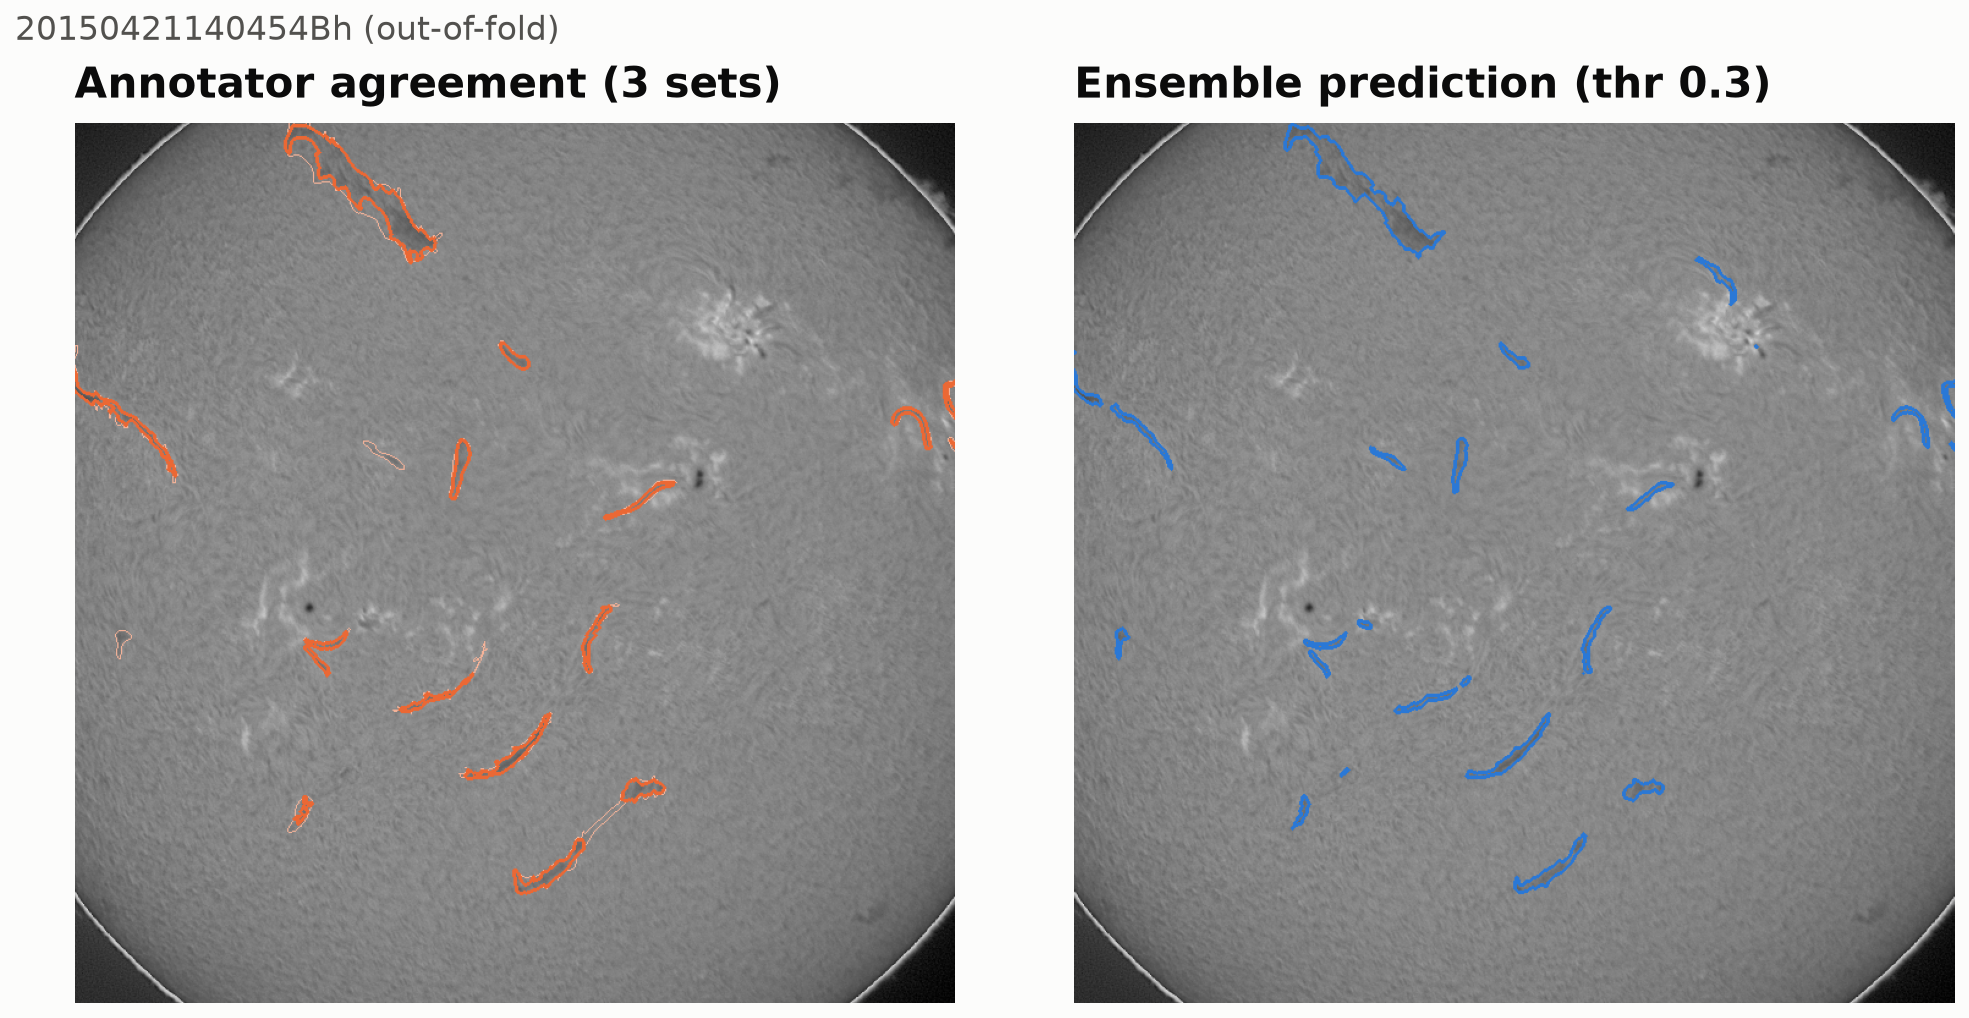

In [8]:
from IPython.display import Image
Image(os.path.join(ROOT, 'report', 'fig_overlay.png'), width=900)